# Qdislib — 07 · Cutting a quantum image (hands-on)

**The key idea: a handful of qubits holds a whole image.** With QPIE
(Quantum Probability Image Encoding), an `n`-qubit state is a probability
distribution over `2**n` bitstrings — read each bitstring as a **pixel
address** and its probability as the pixel **brightness**. So **4 qubits
index all 16 rows** (`2**4 = 16`), 4 more index all 16 columns, and just
**8 qubits encode the entire 16×16 = 256-pixel image** — an *exponential*
packing (8 numbers of hardware for 256 pixels).

That packing is exactly *why you'd cut*: an image that needs 8 qubits can be
run as **two independent 4-qubit halves** — the rows and the columns — and
then reassembled. In this notebook you'll encode an image, apply a quantum
transform, **cut the 8-qubit circuit into two 4-qubit pieces**, and rebuild
the full image with `gate_cutting_sampling` (which reconstructs the whole
output *distribution*, not just an expectation value).

Here's the whole story you'll build — encode → transform → cut & reconstruct:

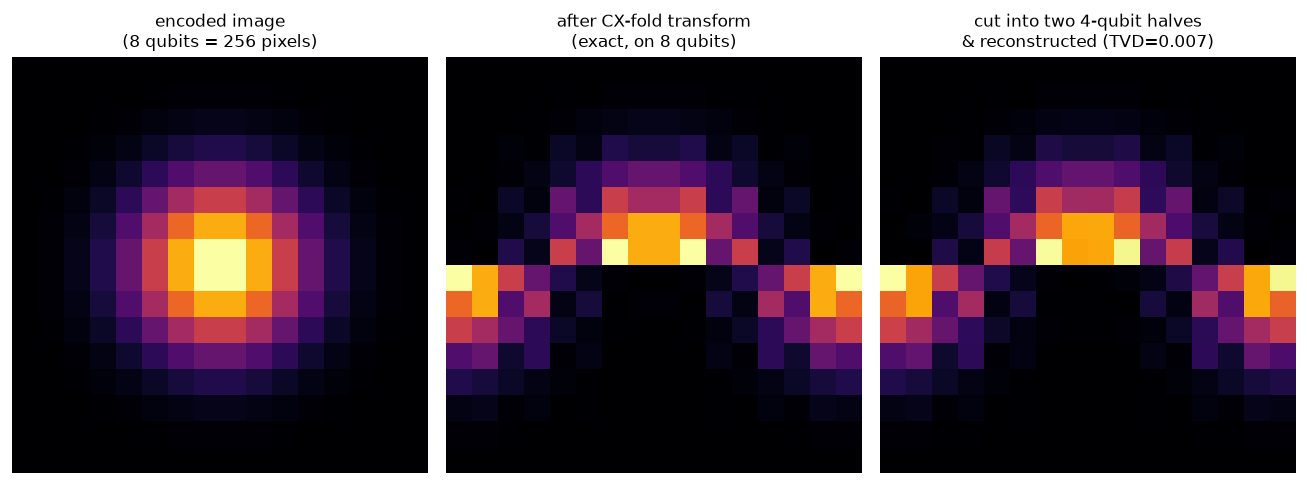

Look for the **🔧 Your turn** cells: change a line, re-run, watch it change.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import StatePreparation
import qiskit.quantum_info as qi
import Qdislib as qd

N_ROW = N_COL = 4          # 4 row qubits + 4 column qubits
N = N_ROW + N_COL          # -> 16 x 16 = 256 pixels


def brightness_profile(n_bits, center, width):
    """Amplitudes whose |.|**2 form a Gaussian bump over 2**n_bits values."""
    x = np.arange(2 ** n_bits)
    p = np.exp(-0.5 * ((x - center) / width) ** 2)
    return np.sqrt(p / p.sum())


def to_image(distribution):
    """{bitstring: probability}  ->  16x16 array (row bits | column bits)."""
    image = np.zeros((2 ** N_ROW, 2 ** N_COL))
    for bitstring, prob in distribution.items():
        row = int(bitstring[:N_ROW][::-1], 2)
        col = int(bitstring[N_ROW:][::-1], 2)
        image[row, col] += prob
    return image


def show(images, titles):
    fig, axes = plt.subplots(1, len(images), figsize=(4 * len(images), 4))
    for ax, img, title in zip(np.atleast_1d(axes), images, titles):
        ax.imshow(img, cmap='inferno'); ax.set_title(title); ax.axis('off')
    plt.show()

## 1. Encode the image  ·  *4 qubits → 16 positions*

We load a **row** brightness profile onto the 4 row qubits and a **column**
profile onto the 4 column qubits. Each 4-qubit register spans all
`2**4 = 16` positions along its axis. Preparing the two registers
*independently* makes the image **separable** — a pure outer product
`row_profile ⊗ column_profile`, i.e. a smooth blob.

In [ ]:
def encode_image(transform):
    qc = QuantumCircuit(N)
    # QPIE: load the row and column brightness profiles (a smooth Gaussian bump).
    qc.append(StatePreparation(brightness_profile(N_ROW, center=7.5, width=2.2)),
              range(N_ROW))
    qc.append(StatePreparation(brightness_profile(N_COL, center=7.5, width=2.2)),
              range(N_ROW, N))
    qc = transpile(qc, basis_gates=['ry', 'rz', 'cx', 'cz', 'h', 'x'],
                   optimization_level=1)
    if transform:
        # TRANSFORM (step 2): fold rows into columns with two CX gates --
        # each ties a column bit to a row bit  (col_bit ^= row_bit).
        qc.cx(0, N_ROW)
        qc.cx(N_ROW - 1, N - 1)
    return qc


def exact_image(qc):
    """The true image, from the exact statevector (our ground truth)."""
    probs = np.abs(qi.Statevector(qc).data) ** 2
    dist = {''.join(str((i >> q) & 1) for q in range(N)): probs[i]
            for i in range(2 ** N)}
    return to_image(dist)


show([exact_image(encode_image(transform=False))], ['separable image (a blob)'])

## 2. Transform: fold rows into columns

Now we couple the two registers with two `CX` (controlled-NOT) gates, each
from a **row qubit to a column qubit**. A `CX` sets `col_bit ^= row_bit`, so
the **column address is XOR-shifted by the row address** — each row moves
horizontally by an amount that depends on the row, which visibly **folds**
the image (the blob wraps into an arc).

Crucially, this coupling **entangles** the row and column registers: the
image is no longer a separable outer product, so it genuinely needs all 8
qubits *together* — which is what makes cutting it non-trivial. (These two
`CX` gates double as our cut points in step 3.)

In [ ]:
show([exact_image(encode_image(transform=False)),
      exact_image(encode_image(transform=True))],
     ['before (separable blob)', 'after (CX fold: rows -> columns)'])

### 🔧 Your turn (1)

Change the **blob**: move its center or make it wider/narrower, and re-run
the cell below. Try `center=4.0` (top-left) or `width=1.0` (sharper).

In [ ]:
def brightness_profile(n_bits, center, width):        # <-- edit center / width
    x = np.arange(2 ** n_bits)
    p = np.exp(-0.5 * ((x - center) / width) ** 2)
    return np.sqrt(p / p.sum())

show([exact_image(encode_image(transform=True))], ['your transformed image'])

## 3. The image is an 8-qubit circuit — cut it in two

Suppose our device only has ~4 qubits. `find_cut` looks for a good place to
split the circuit; here it finds the two row↔column `CZ` gates, which
separate the **row half** from the **column half**.

In [ ]:
transformed = encode_image(transform=True)
cut = qd.find_cut(transformed, gate_cut=True, wire_cut=False, max_qubits=N_ROW)
print('cut gates:', cut)   # the two row<->column entanglers

## 4. Reconstruct the image by sampling the pieces

`gate_cutting_sampling` samples each subcircuit independently and recombines
them (via the gate-cut quasiprobability decomposition) into the **full
output distribution** — the reconstructed image. Two cuts means `6**2 = 36`
subcircuit configurations, each a small 4-qubit circuit.

In [ ]:
distribution = qd.gate_cutting_sampling(transformed, cut, shots=200_000,
                                        software='qiskit')
reconstructed = to_image(distribution)

show([exact_image(transformed), reconstructed],
     ['transformed (exact)', 'reconstructed from the 2 halves'])

tvd = 0.5 * np.abs(exact_image(transformed) - reconstructed).sum()
print(f'total-variation distance vs exact: {tvd:.4f}   (~shot noise)')

### 🔧 Your turn (2)

Fewer shots ⇒ a noisier reconstruction. Re-run the reconstruction with
`shots=20_000` and compare the image and the TVD. (Sampling reconstruction
carries a quasiprobability overhead, so it needs more shots than a plain
expectation value.)

In [ ]:
distribution = qd.gate_cutting_sampling(transformed, cut, shots=20_000,   # <-- change
                                        software='qiskit')
noisy = to_image(distribution)
show([reconstructed, noisy], ['200k shots', '20k shots'])
print('TVD:', round(0.5 * np.abs(exact_image(transformed) - noisy).sum(), 4))

## 5. Run it distributed with PyCOMPSs

Each of the 36 subcircuit configurations is an **independent task**, so on a
cluster they sample **in parallel** — the call is exactly the same. Put the
code in a script and launch it with `runcompss`; Qdislib submits each
subcircuit as a PyCOMPSs `@task` and waits on the results for you.

In [ ]:
# my_image_app.py  --  run with:  runcompss --python my_image_app.py
import Qdislib as qd

transformed = encode_image(transform=True)
cut = qd.find_cut(transformed, gate_cut=True, wire_cut=False, max_qubits=4)
# The 36 subcircuits sample in parallel across the available workers:
distribution = qd.gate_cutting_sampling(transformed, cut, shots=200_000,
                                        software='qiskit')

## Recap & bonus

You encoded an image as a quantum distribution, transformed it by
entangling rows and columns, **cut the 8-qubit circuit into two 4-qubit
halves**, and rebuilt the image by sampling — reconstructing the full
distribution, not just one number.

**🔧 Bonus:** bump the resolution to `32×32` by setting `N_ROW = N_COL = 5`
(re-run from the setup cell). The circuit grows to 10 qubits and each half
to 5 — but it's still just **two cuts** (the cost of cutting scales with the
number of cuts, `6**n_cuts`, not the circuit size).